### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

### **1. Bias and Variance**

A model trained on **different samples** of the same process gives **different predictions**. The expected squared error at a point $x$ decomposes into:

$$E\big[(y - \hat{f}(x))^2\big] = \underbrace{\big(E[\hat{f}(x)] - f(x)\big)^2}_{\text{Bias}^2} + \underbrace{E\big[(\hat{f}(x) - E[\hat{f}(x)])^2\big]}_{\text{Variance}} + \underbrace{\sigma^2}_{\text{Noise}}$$

* **Bias:** **systematic** error – the *average* model misses the truth → **underfitting**
* **Variance:** **instability** – the model changes with the training set → **overfitting**
* $\sigma^2$: **irreducible noise**

### **2. Estimating Bias and Variance**

We **simulate** the expectation: draw **many training sets** from a known process ($y = \sin(2\pi x) + \epsilon$), train the same model on each and compare the predictions at fixed points.

* $\text{bias}^2$ = mean of (average prediction − truth)², minus the Monte Carlo error $\text{var}/n_{sims}$
* variance = mean variance of the predictions across training sets

In [3]:
#True Function, Training Sets and Polynomial Model
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def true_function(x):
    return np.sin(2 * np.pi * x)

def make_data(n, noise=0.3, seed=0):
    rng = np.random.default_rng(seed)
    x = rng.random(n)
    return x.reshape(-1, 1), true_function(x) + rng.normal(0, noise, n)

def poly_model(degree, reg=None):
    reg = LinearRegression() if reg is None else reg
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), reg)

x_eval = np.linspace(0.02, 0.98, 100).reshape(-1, 1)         # fixed points where predictions are compared
f_eval = true_function(x_eval.ravel())

In [4]:
#Functions: Train on Many Training Sets and Decompose the Error
def simulate(model_factory, n_train=30, noise=0.3, n_sims=300, seed0=1000):
    """Predictions at x_eval of the same model trained on n_sims different training sets."""
    preds = np.empty((n_sims, len(x_eval)))
    for s in range(n_sims):
        X, y = make_data(n_train, noise, seed0 + s)
        preds[s] = model_factory().fit(X, y).predict(x_eval)
    return preds

def decompose(preds, noise=0.3):
    n_sims = len(preds)
    var_x = preds.var(axis=0, ddof=1)
    # (mean - f)² also contains var/n_sims: the average of finitely many predictions is itself noisy
    bias2 = max(np.mean((preds.mean(axis=0) - f_eval) ** 2 - var_x / n_sims), 0.0)
    variance = np.mean(var_x)
    return {"bias²": bias2, "variance": variance, "noise²": noise ** 2, "expected error": bias2 + variance + noise ** 2}

FLOOR = 1e-4          # bias² ≈ 0 is drawn at this floor in the log-scale plots

def show(df):
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(df)

#### **Checking the Decomposition**

If the formula is right, the error **measured** with fresh noisy targets must match $\text{bias}^2 + \text{variance} + \sigma^2$:

In [5]:
#Check the Decomposition: Measured Error vs Bias² + Variance + Noise²
rng = np.random.default_rng(0)
rows = []
for d in [1, 4, 8]:
    preds = simulate(lambda: poly_model(d))
    y_new = f_eval + rng.normal(0, 0.3, size=preds.shape)         # fresh noisy targets for every training set
    rows.append({"degree": d, "measured MSE": np.mean((y_new - preds) ** 2), **decompose(preds)})
show(pd.DataFrame(rows).set_index("degree"))

,measured MSE,bias²,variance,noise²,expected error
degree,,,,,
1,0.2921,0.1764,0.0218,0.0900,0.2882
4,0.1176,0.0034,0.0233,0.0900,0.1167
8,3.4629,0.0021,3.3740,0.0900,3.4660


### **3. Many Fits: Bias and Variance Visualised**

Each grey line is the **same model** trained on a **different** training set; the red line is the **average prediction**.

* **Degree 1:** lines almost identical (low variance), but the average is far from the truth (**high bias**)
* **Degree 8:** the average is close to the truth (low bias), but the lines scatter wildly (**high variance**)

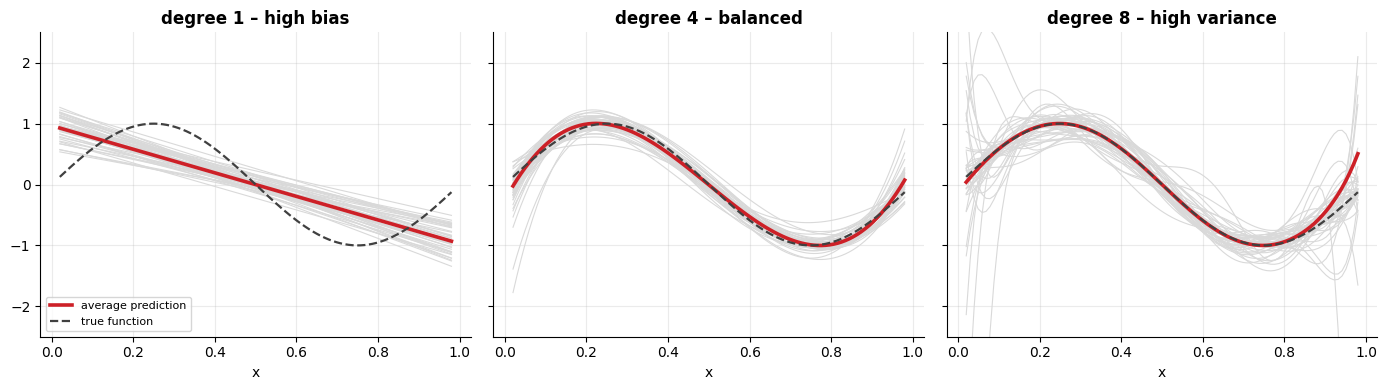

,bias²,variance,noise²,expected error
model,,,,
degree 1 – high bias,0.1764,0.0218,0.0900,0.2882
degree 4 – balanced,0.0034,0.0233,0.0900,0.1167
degree 8 – high variance,0.0021,3.3740,0.0900,3.4660


In [6]:
#Same Model Trained on 40 Different Training Sets
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
rows = []
for ax, d, name in zip(axes, [1, 4, 8], ["degree 1 – high bias", "degree 4 – balanced", "degree 8 – high variance"]):
    preds = simulate(lambda: poly_model(d))
    for p in preds[:40]:
        ax.plot(x_eval, p, color=LIGHT, lw=0.8)
    ax.plot(x_eval, np.clip(preds.mean(axis=0), -3, 3), color=RED, lw=2.6, label="average prediction")
    ax.plot(x_eval, f_eval, color=DARK, ls="--", lw=1.6, label="true function")
    ax.set_ylim(-2.5, 2.5); ax.set_title(name); ax.set_xlabel("x")
    rows.append({"model": name, **decompose(preds)})
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()
show(pd.DataFrame(rows).set_index("model"))

### **4. The Bias–Variance Trade-off**

Increasing the complexity (polynomial degree) **lowers the bias** and **raises the variance**. The best model sits where the **expected error** is lowest.

,degree,bias²,variance,noise²,expected error
0,1,0.1764,0.0218,0.0900,0.2882
1,2,0.1751,0.0418,0.0900,0.3069
2,3,0.0034,0.0153,0.0900,0.1087
3,4,0.0034,0.0233,0.0900,0.1167
4,5,0.0000,0.0474,0.0900,0.1374
5,6,0.0013,0.1472,0.0900,0.2385
6,7,0.0024,0.3551,0.0900,0.4475
7,8,0.0021,3.3740,0.0900,3.4660
8,9,0.0012,4.9321,0.0900,5.0233
9,10,0.0000,20.6039,0.0900,20.6939


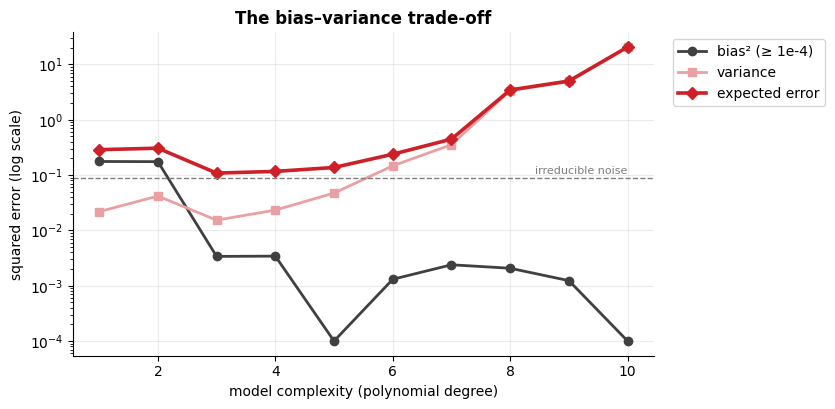

degree with the lowest expected error: 3


In [7]:
#Bias² and Variance by Polynomial Degree ( 300 Training Sets )
degrees = range(1, 11)
rows = [{"degree": d, **decompose(simulate(lambda: poly_model(d)))} for d in degrees]
tradeoff = pd.DataFrame(rows)
show(tradeoff)

plt.figure()
plt.plot(tradeoff["degree"], np.maximum(tradeoff["bias²"], FLOOR), marker="o", color=DARK, lw=2, label="bias² (≥ 1e-4)")
plt.plot(tradeoff["degree"], tradeoff["variance"], marker="s", color=SOFT, lw=2, label="variance")
plt.plot(tradeoff["degree"], tradeoff["expected error"], marker="D", color=RED, lw=2.6, label="expected error")
plt.axhline(0.3 ** 2, color=GRAY, ls="--", lw=1); plt.text(10, 0.3 ** 2 * 1.15, "irreducible noise", ha="right", fontsize=8, color=GRAY)
plt.yscale("log"); plt.xlabel("model complexity (polynomial degree)"); plt.ylabel("squared error (log scale)")
plt.title("The bias–variance trade-off"); plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()
print("degree with the lowest expected error:", int(tradeoff.loc[tradeoff["expected error"].idxmin(), "degree"]))

Note that the expected error **never goes below the noise** ($0.09$): the trade-off only decides how close we get to it.

### **5. Bias and Variance along x**

The decomposition holds **at each point**. Where does a flexible model lose control?

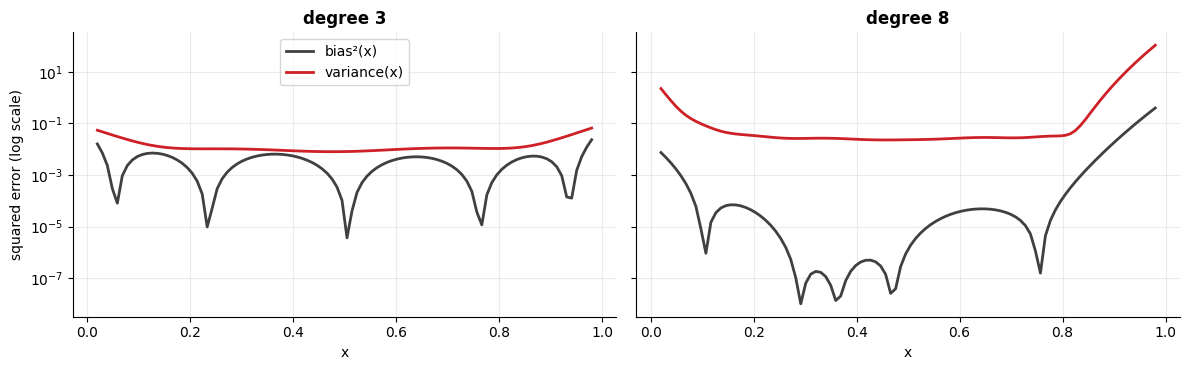

In [8]:
#Bias²(x) and Variance(x) ( Degree 3 vs Degree 8 )
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, d in zip(axes, [3, 8]):
    preds = simulate(lambda: poly_model(d))
    ax.plot(x_eval, (preds.mean(axis=0) - f_eval) ** 2 + 1e-8, color=DARK, lw=2, label="bias²(x)")
    ax.plot(x_eval, preds.var(axis=0), color=RED, lw=2, label="variance(x)")
    ax.set_yscale("log"); ax.set_title(f"degree {d}"); ax.set_xlabel("x")
axes[0].set_ylabel("squared error (log scale)"); axes[0].legend(loc="upper center")
plt.tight_layout(); plt.show()

The variance explodes near the **edges** of the data (little information there); in the middle the flexible model is stable.

### **6. What Changes Bias and Variance?**

Three levers: the **amount of data**, the **noise** and the **regularisation**.

#### **Training Set Size**

More data **reduces the variance**; it does **not** fix a biased model.

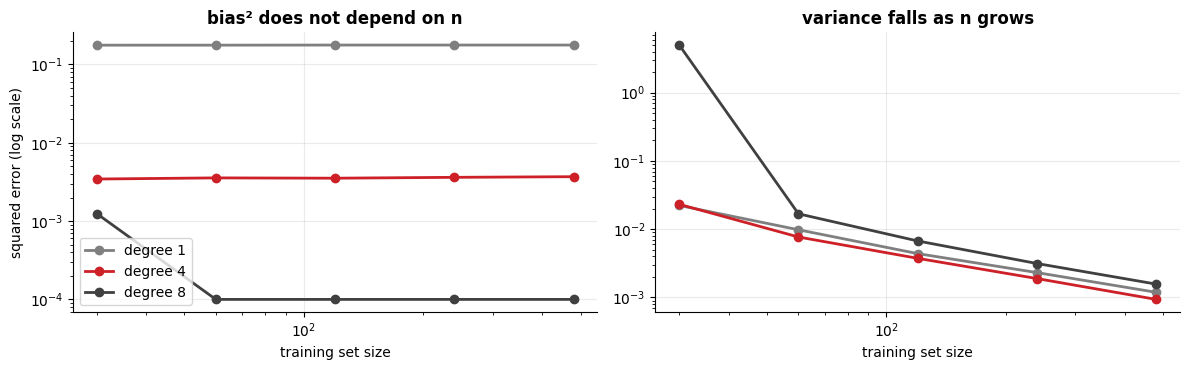

bias²  variance  noise²  expected error
degree n_train                                         
1      30      0.1764    0.0223  0.0900          0.2887
       120     0.1770    0.0044  0.0900          0.2714
       480     0.1770    0.0012  0.0900          0.2682
4      30      0.0034    0.0232  0.0900          0.1166
       120     0.0035    0.0037  0.0900          0.0973
       480     0.0037    0.0009  0.0900          0.0946
8      30      0.0013    4.9808  0.0900          5.0720
       120     0.0000    0.0067  0.0900          0.0967
       480     0.0000    0.0016  0.0900          0.0916

In [9]:
#Bias² and Variance by Training Set Size ( Degrees 1, 4 and 8 )
sizes = [30, 60, 120, 240, 480]
rows = []
for d in [1, 4, 8]:
    for n in sizes:
        rows.append({"degree": d, "n_train": n, **decompose(simulate(lambda: poly_model(d), n_train=n, n_sims=200))})
by_size = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for d, color in zip([1, 4, 8], [GRAY, RED, DARK]):
    sub = by_size[by_size["degree"] == d]
    axes[0].plot(sub["n_train"], np.maximum(sub["bias²"], FLOOR), marker="o", color=color, lw=2, label=f"degree {d}")
    axes[1].plot(sub["n_train"], sub["variance"], marker="o", color=color, lw=2, label=f"degree {d}")
for ax, t in zip(axes, ["bias² does not depend on n", "variance falls as n grows"]):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("training set size"); ax.set_title(t)
axes[0].set_ylabel("squared error (log scale)"); axes[0].legend()
plt.tight_layout(); plt.show()
show(by_size[by_size["n_train"].isin([30, 120, 480])].set_index(["degree", "n_train"]))

#### **Noise Level**

Noise adds the irreducible $\sigma^2$ and also **inflates the variance** of a flexible model (it has more noise to memorise); the bias **barely changes**.

In [10]:
#Bias² and Variance by Noise Level ( Degrees 1, 4 and 8 )
rows = []
for d in [1, 4, 8]:
    for s in [0.1, 0.3, 0.6, 1.0]:
        rows.append({"degree": d, "noise σ": s, **decompose(simulate(lambda: poly_model(d), noise=s, n_sims=200), noise=s)})
show(pd.DataFrame(rows).set_index(["degree", "noise σ"]))

bias²  variance  noise²  expected error
degree noise σ                                         
1      0.1000  0.1762    0.0165  0.0100          0.2027
       0.3000  0.1764    0.0223  0.0900          0.2887
       0.6000  0.1768    0.0416  0.3600          0.5784
       1.0000  0.1773    0.0876  1.0000          1.2648
4      0.1000  0.0034    0.0060  0.0100          0.0194
       0.3000  0.0034    0.0232  0.0900          0.1166
       0.6000  0.0036    0.0815  0.3600          0.4450
       1.0000  0.0038    0.2199  1.0000          1.2237
8      0.1000  0.0001    0.5541  0.0100          0.5643
       0.3000  0.0013    4.9808  0.0900          5.0720
       0.6000  0.0049   19.9168  0.3600         20.2817
       1.0000  0.0135   55.3173  1.0000         56.3308

#### **Regularisation Strength**

**Ridge** penalises large coefficients. A larger $\alpha$ **raises the bias** and **lowers the variance**. Degree-10 polynomial:

,bias²,variance,noise²,expected error
alpha,,,,
0.0001,0.0026,0.3925,0.0900,0.4850
0.0010,0.0005,0.1503,0.0900,0.2408
0.0100,0.0024,0.0562,0.0900,0.1486
0.1000,0.0272,0.0634,0.0900,0.1807
1.0000,0.0678,0.0503,0.0900,0.2081
10.0000,0.1223,0.0178,0.0900,0.2301
100.0000,0.2913,0.0288,0.0900,0.4101
1000.0000,0.4443,0.0207,0.0900,0.5550


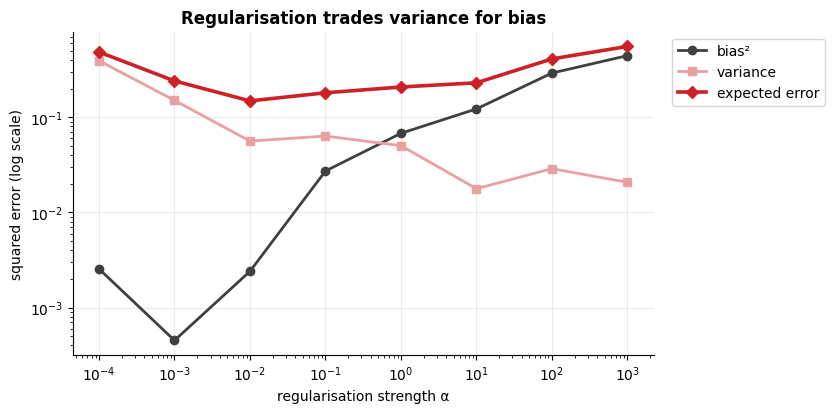

In [11]:
#Bias² and Variance by Regularisation Strength ( Ridge, Degree 10 )
from sklearn.linear_model import Ridge

alphas = np.logspace(-4, 3, 8)
rows = [{"alpha": a, **decompose(simulate(lambda: poly_model(10, Ridge(alpha=a)), n_sims=200))} for a in alphas]
ridge_df = pd.DataFrame(rows)
show(ridge_df.set_index("alpha"))

plt.figure()
plt.plot(ridge_df["alpha"], np.maximum(ridge_df["bias²"], FLOOR), marker="o", color=DARK, lw=2, label="bias²")
plt.plot(ridge_df["alpha"], ridge_df["variance"], marker="s", color=SOFT, lw=2, label="variance")
plt.plot(ridge_df["alpha"], ridge_df["expected error"], marker="D", color=RED, lw=2.6, label="expected error")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("regularisation strength α"); plt.ylabel("squared error (log scale)")
plt.title("Regularisation trades variance for bias"); plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

### **7. Other Models**

The same idea holds for any algorithm; only the **complexity knob** changes:

* **k-NN:** small $k$ → high variance · large $k$ → high bias
* **Decision tree:** deep → high variance · shallow → high bias

In [12]:
#k-NN Regressor: Bias² and Variance by k
from sklearn.neighbors import KNeighborsRegressor

ks = [1, 2, 3, 5, 8, 12, 20, 29]
knn_df = pd.DataFrame([{"k": k, **decompose(simulate(lambda: KNeighborsRegressor(n_neighbors=k), n_sims=200))} for k in ks])
show(knn_df.set_index("k"))

,bias²,variance,noise²,expected error
k,,,,
1,0.0003,0.1022,0.0900,0.1925
2,0.0010,0.0559,0.0900,0.1469
3,0.0024,0.0431,0.0900,0.1355
5,0.0097,0.0328,0.0900,0.1325
8,0.0270,0.0277,0.0900,0.1448
12,0.0529,0.0284,0.0900,0.1713
20,0.1953,0.0394,0.0900,0.3247
29,0.5072,0.0218,0.0900,0.6189


,bias²,variance,noise²,expected error
depth,,,,
1,0.0593,0.0535,0.0900,0.2028
2,0.0189,0.0754,0.0900,0.1844
3,0.0021,0.0683,0.0900,0.1604
4,0.0008,0.0803,0.0900,0.1710
5,0.0002,0.0909,0.0900,0.1811
6,0.0003,0.0977,0.0900,0.1880
8,0.0003,0.1018,0.0900,0.1921


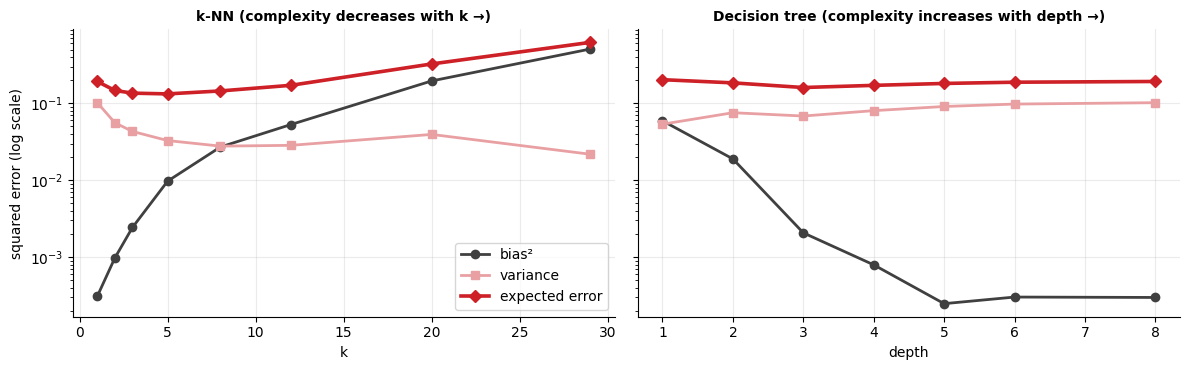

In [13]:
#Decision Tree Regressor: Bias² and Variance by Depth
from sklearn.tree import DecisionTreeRegressor

depths = [1, 2, 3, 4, 5, 6, 8]
tree_df = pd.DataFrame([{"depth": d, **decompose(simulate(lambda: DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE), n_sims=200))} for d in depths])
show(tree_df.set_index("depth"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, df, key, title in zip(axes, [knn_df, tree_df], ["k", "depth"], ["k-NN (complexity decreases with k →)", "Decision tree (complexity increases with depth →)"]):
    ax.plot(df[key], np.maximum(df["bias²"], FLOOR), marker="o", color=DARK, lw=2, label="bias²")
    ax.plot(df[key], df["variance"], marker="s", color=SOFT, lw=2, label="variance")
    ax.plot(df[key], df["expected error"], marker="D", color=RED, lw=2.6, label="expected error")
    ax.set_yscale("log"); ax.set_xlabel(key); ax.set_title(title, fontsize=10)
axes[0].set_ylabel("squared error (log scale)"); axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

### **8. Ensembles: Bagging and Boosting**

Two classic ways to **escape** the trade-off:

* **Bagging (Random Forest):** averages many **deep** (high-variance) trees → **lower variance**, similar bias
* **Boosting:** adds many **shallow** (high-bias) trees, each correcting the previous ones → **lower bias**

,bias²,variance,noise²,expected error
"tree, depth 1 (stump)",0.0589,0.0554,0.0900,0.2043
"tree, depth 6",0.0001,0.0986,0.0900,0.1888
"bagged trees, depth 6 (50)",0.0010,0.0519,0.0900,0.1429
"boosting, stumps (100)",0.0093,0.0376,0.0900,0.1370


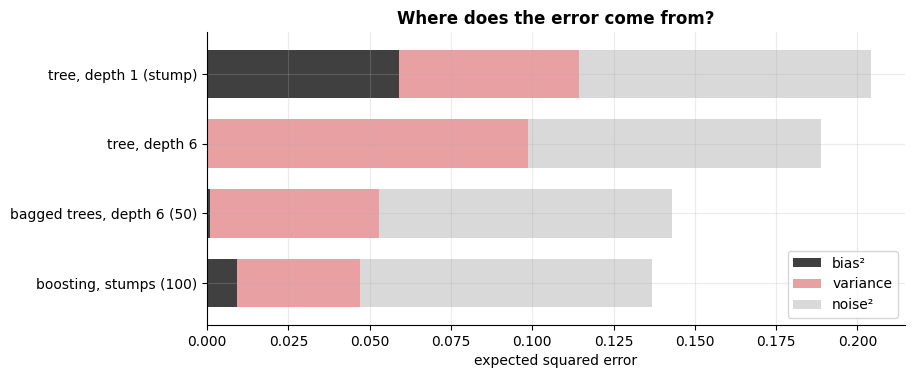

In [14]:
#Compare Single Trees, Bagging and Boosting
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor     # RandomForestRegressor is used in section 10

models = {
    "tree, depth 1 (stump)":        lambda: DecisionTreeRegressor(max_depth=1, random_state=RANDOM_STATE),
    "tree, depth 6":                lambda: DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
    "bagged trees, depth 6 (50)":   lambda: BaggingRegressor(DecisionTreeRegressor(max_depth=6), n_estimators=50, random_state=RANDOM_STATE),
    "boosting, stumps (100)":       lambda: GradientBoostingRegressor(n_estimators=100, max_depth=1, learning_rate=0.1, random_state=RANDOM_STATE),
}
ens = pd.DataFrame({name: decompose(simulate(f, n_sims=150)) for name, f in models.items()}).T
show(ens)

ens[["bias²", "variance", "noise²"]].plot.barh(stacked=True, color=[DARK, SOFT, LIGHT], figsize=(9, 3.8), width=0.7)
plt.xlabel("expected squared error"); plt.title("Where does the error come from?"); plt.gca().invert_yaxis()
plt.show()

### **9. Bias and Variance in Classification**

With the **0-1 loss** the idea is the same, but less clean. Train on many training sets and take the **main prediction** (majority vote) at each test point:

* **bias:** fraction of points where the main prediction is **wrong**
* **variance:** how often a single model **disagrees** with the main prediction

In [15]:
#Functions: Bias and Variance for Classifiers ( Moons Dataset )
from sklearn.datasets import make_moons

X_test_c, y_test_c = make_moons(n_samples=400, noise=0.35, random_state=99999)

def simulate_clf(model_factory, n_train=60, n_sims=200, seed0=2000):
    preds = np.empty((n_sims, len(y_test_c)), dtype=int)
    for s in range(n_sims):
        X, y = make_moons(n_samples=n_train, noise=0.35, random_state=seed0 + s)
        preds[s] = model_factory().fit(X, y).predict(X_test_c)
    return preds

def decompose_clf(preds):
    main = (preds.mean(axis=0) >= 0.5).astype(int)                   # majority vote across training sets
    return {"error": np.mean(preds != y_test_c), "bias": np.mean(main != y_test_c), "variance": np.mean(preds != main)}

,error,bias,variance
k,,,
1,0.1856,0.1025,0.1408
3,0.1500,0.1075,0.0962
5,0.1376,0.1100,0.0781
9,0.1276,0.1075,0.0615
15,0.1291,0.1100,0.0495
25,0.1589,0.1575,0.0401
41,0.2251,0.2350,0.0268
59,0.2814,0.2900,0.0559


,error,bias,variance
depth,,,
1,0.2382,0.2075,0.1412
2,0.1614,0.1300,0.0977
3,0.1640,0.1325,0.1026
4,0.1922,0.1125,0.1429
6,0.1976,0.1100,0.1543
8,0.1985,0.1100,0.1557
12,0.1991,0.1050,0.1565


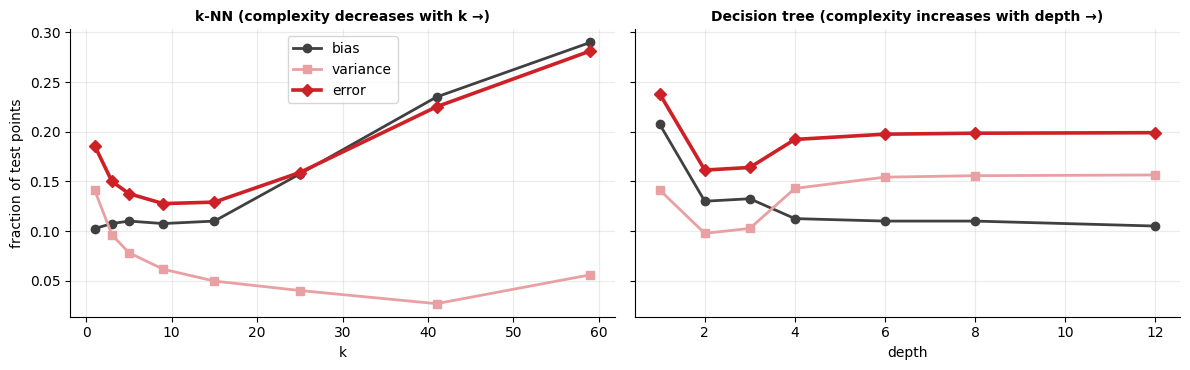

In [16]:
#k-NN and Decision Tree Classifiers: Bias and Variance
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

knn_c = pd.DataFrame([{"k": k, **decompose_clf(simulate_clf(lambda: KNeighborsClassifier(n_neighbors=k)))} for k in [1, 3, 5, 9, 15, 25, 41, 59]])
tree_c = pd.DataFrame([{"depth": d, **decompose_clf(simulate_clf(lambda: DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)))} for d in [1, 2, 3, 4, 6, 8, 12]])
show(knn_c.set_index("k")); show(tree_c.set_index("depth"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, df, key, title in zip(axes, [knn_c, tree_c], ["k", "depth"], ["k-NN (complexity decreases with k →)", "Decision tree (complexity increases with depth →)"]):
    ax.plot(df[key], df["bias"], marker="o", color=DARK, lw=2, label="bias")
    ax.plot(df[key], df["variance"], marker="s", color=SOFT, lw=2, label="variance")
    ax.plot(df[key], df["error"], marker="D", color=RED, lw=2.6, label="error")
    ax.set_xlabel(key); ax.set_title(title, fontsize=10)
axes[0].set_ylabel("fraction of test points"); axes[0].legend(loc="upper center")
plt.tight_layout(); plt.show()

As flexibility grows the **bias tends to fall** and the **variance to rise** (a depth-1 stump is also unstable: its split flips between the two features). With the 0-1 loss the terms do **not** add up exactly to the error.

### **10. Diagnosing in Practice**

Real data do not give $f(x)$, so we use **proxies**:

* **High bias:** training error **high** and close to the validation error
* **High variance:** training error **low**, validation error **much higher**

Models compared on **Diabetes** (5-fold CV) against a baseline that always predicts the mean.

In [17]:
#Training vs Cross-Validated Error on a Real Dataset ( Diabetes )
from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

Xd, yd = load_diabetes(return_X_y=True, as_frame=True)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

real_models = {
    "baseline (always the mean)": DummyRegressor(),
    "linear regression":          LinearRegression(),
    "decision tree (no limit)":   DecisionTreeRegressor(random_state=RANDOM_STATE),
    "random forest (200)":        RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "gradient boosting":          GradientBoostingRegressor(random_state=RANDOM_STATE),
}
rows = []
for name, m in real_models.items():
    r = cross_validate(m, Xd, yd, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
    rows.append((name, abs(r["train_score"].mean()), abs(r["test_score"].mean())))
real = pd.DataFrame(rows, columns=["model", "train MSE", "CV MSE"]).set_index("model")
real["gap (CV − train)"] = real["CV MSE"] - real["train MSE"]
real["CV MSE / baseline"] = real["CV MSE"] / real.loc["baseline (always the mean)", "CV MSE"]
real.round(2)

,train MSE,CV MSE,gap (CV − train),CV MSE / baseline
model,,,,
baseline (always the mean),5925.48,5970.10,44.61,1.00
linear regression,2842.99,3015.38,172.39,0.51
decision tree (no limit),0.00,6621.81,6621.81,1.11
random forest (200),475.33,3324.15,2848.82,0.56
gradient boosting,934.57,3391.25,2456.68,0.57


* **Linear regression:** small gap, but the error stays high → **bias** (or noise: with real data we cannot separate them)
* **Tree without limit:** training error ≈ 0 and a huge gap → **variance**
* **Forest and boosting:** smaller gaps → the ensembles **reduce the variance**

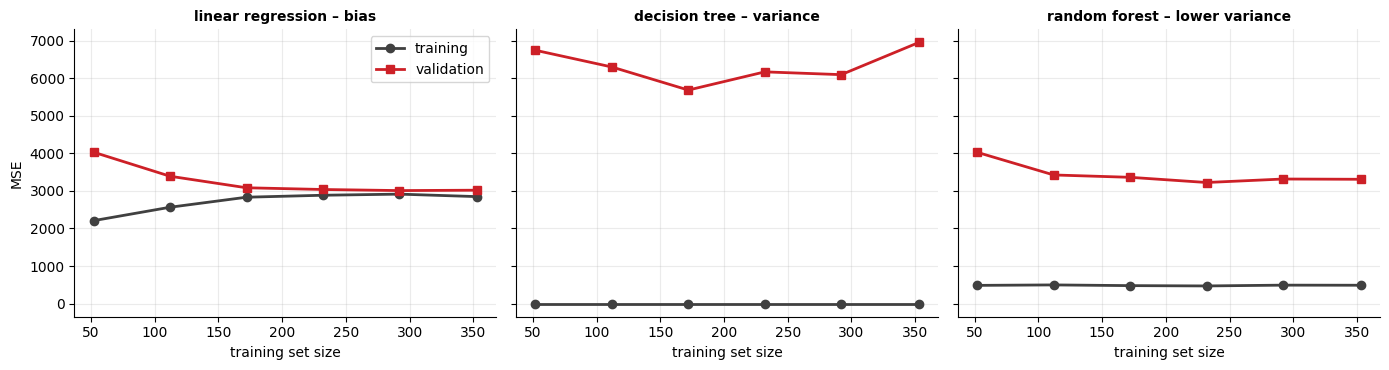

In [18]:
#Learning Curves: Linear Regression vs Deep Tree vs Random Forest
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (name, m) in zip(axes, [("linear regression – bias", LinearRegression()),
                                ("decision tree – variance", DecisionTreeRegressor(random_state=RANDOM_STATE)),
                                ("random forest – lower variance", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE))]):
    sizes, tr, va = learning_curve(m, Xd, yd, train_sizes=np.linspace(0.15, 1.0, 6), cv=cv, scoring="neg_mean_squared_error")
    ax.plot(sizes, -tr.mean(axis=1), marker="o", color=DARK, lw=2, label="training")
    ax.plot(sizes, -va.mean(axis=1), marker="s", color=RED, lw=2, label="validation")
    ax.set_title(name, fontsize=10); ax.set_xlabel("training set size")
axes[0].set_ylabel("MSE"); axes[0].legend()
plt.tight_layout(); plt.show()

* **Linear regression:** the curves **converge** to a high error → more data will not help
* **Tree:** training error ≈ 0 and a validation error that stays **high and noisy** – data alone do not fix such a high variance
* **Forest:** a much **lower validation error** than the single tree – averaging cuts the variance

### **11. Summary**

| | **High bias** | **High variance** |
|---|---|---|
| Symptom | training **and** validation error **high** | training error **low**, validation error **much higher** |
| Problem | **underfitting** | **overfitting** |
| Learning curves | converge to a **high** error | **large gap** between training and validation |
| **Reduce it by** | more flexible model · better attributes · less regularisation · **boosting** | more data · regularisation · simpler model · fewer attributes · **bagging / forests** |
| More data helps? | ❌ **No** | ✅ **Yes** (variance falls with $n$, section 6) |

The expected error never goes below the **noise** $\sigma^2$.

#### **Exercises**

1. In section 4, pass `noise=0.6` to `simulate` and `decompose`. Does the best degree change?
2. In section 8, try `max_depth=3` and `n_estimators=300` for the boosting model. What happens to bias and variance?
3. In section 10, add a **Ridge** model and a **k-NN** (with `StandardScaler`). Where do they fall between linear regression and the deep tree?